# Netflix Titles EDA
Exploratory Data Analysis for Month 3, Task 4 of the Data Science Internship.


## 1. Project Objective
- Understand the Netflix Titles dataset.
- Compare Movies and TV Shows.
- Analyze release trends, genres, and countries.
- Generate visualizations and interpret findings.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
SRC_PATH = PROJECT_ROOT / 'src'
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))
from data_cleaning import clean_dataset, load_dataset
from feature_engineering import create_features
OUTPUT_DIRECTORY = PROJECT_ROOT / 'outputs'
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid')


## 2. Load the Dataset


In [2]:
df_raw = load_dataset()
print(f'Raw dataset shape: {df_raw.shape}')
df_raw.head()


Raw dataset shape: (8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


## 3. Data Understanding


In [3]:
df_raw.info()


<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB


In [4]:
df_raw.describe(include='all').T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
show_id,8807,8807,s1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,8807,2,Movie,6131,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,8807,8807,Dick Johnson Is Dead,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
director,6173,4528,Rajiv Chilaka,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cast,7982,7692,David Attenborough,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,7976,748,United States,2818,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_added,8797,1767,"January 1, 2020",109,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,8807.0,NaN,NaN,NaN,2014.180198,8.819312,1925.0,2013.0,2017.0,2019.0,2021.0
rating,8803,17,TV-MA,3207,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,8804,220,1 Season,1793,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
missing_values = df_raw.isnull().sum().sort_values(ascending=False)
missing_values[missing_values > 0]


director      2634
country        831
cast           825
date_added      10
rating           4
duration         3
dtype: int64

In [6]:
print(f'Duplicate rows: {df_raw.duplicated().sum()}')


Duplicate rows: 0


## 4. Data Cleaning and Feature Engineering


In [7]:
df_cleaned = clean_dataset(df_raw)
df = create_features(df_cleaned)
print(f'Cleaned dataset shape: {df_cleaned.shape}')
print(f'Feature-engineered dataset shape: {df.shape}')
df.head()


Cleaned dataset shape: (8807, 12)
Feature-engineered dataset shape: (8807, 16)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,release_decade,is_movie,content_type,added_year
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",2020,1,Movie,2021.0
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2020,0,Tv Show,2021.0
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,2020,0,Tv Show,2021.0
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",2020,0,Tv Show,2021.0
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,2020,0,Tv Show,2021.0


## 5. Movie vs TV Show Distribution


In [8]:
content_counts = df['content_type'].value_counts()
content_counts


content_type
Movie      6131
Tv Show    2676
Name: count, dtype: int64

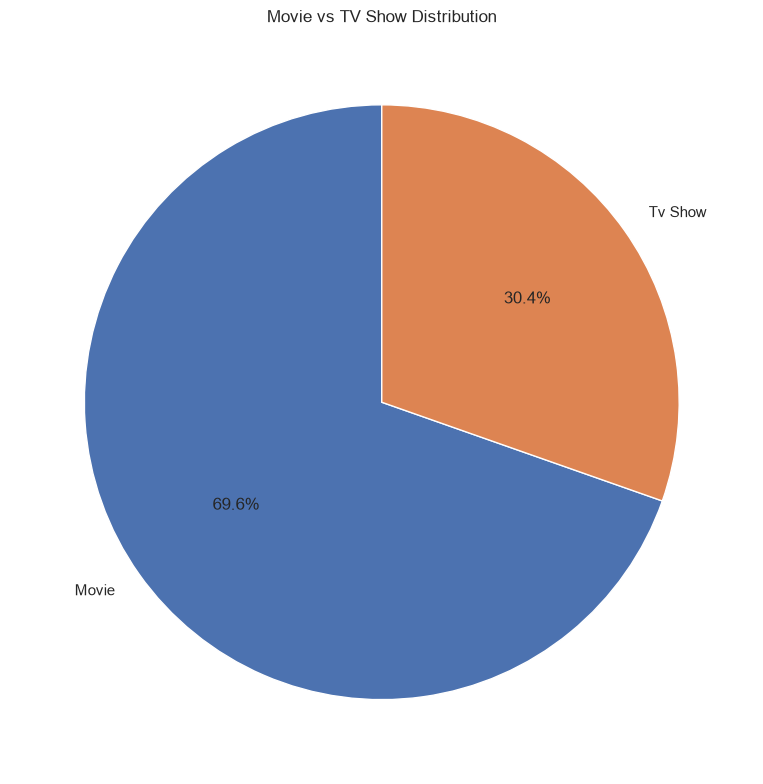

In [9]:
plt.figure(figsize=(8, 8))
plt.pie(content_counts.values, labels=content_counts.index, autopct='%1.1f%%', startangle=90)
plt.title('Movie vs TV Show Distribution')
plt.tight_layout()
plt.show()


## 6. Content Released Per Year


In [10]:
yearly_content = df.groupby('release_year').size().reset_index(name='content_count').sort_values('release_year')
yearly_content.tail()


,release_year,content_count
69,2017,1032
70,2018,1147
71,2019,1030
72,2020,953
73,2021,592


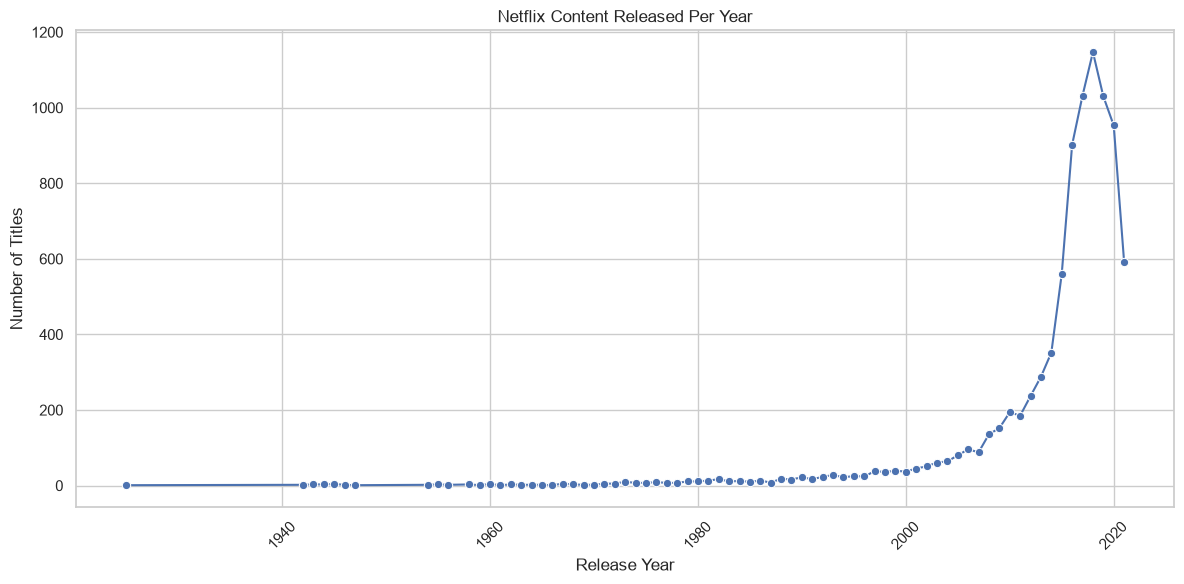

In [11]:
plt.figure(figsize=(12, 6))
sns.lineplot(data=yearly_content, x='release_year', y='content_count', marker='o')
plt.title('Netflix Content Released Per Year')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 7. Top 10 Genres


In [12]:
genre_data = df['listed_in'].dropna().str.split(', ').explode()
top_genres = genre_data.value_counts().head(10).sort_values()
top_genres


listed_in
Romantic Movies              616
Children & Family Movies     641
Independent Movies           756
TV Dramas                    763
Action & Adventure           859
Documentaries                869
International TV Shows      1351
Comedies                    1674
Dramas                      2427
International Movies        2752
Name: count, dtype: int64

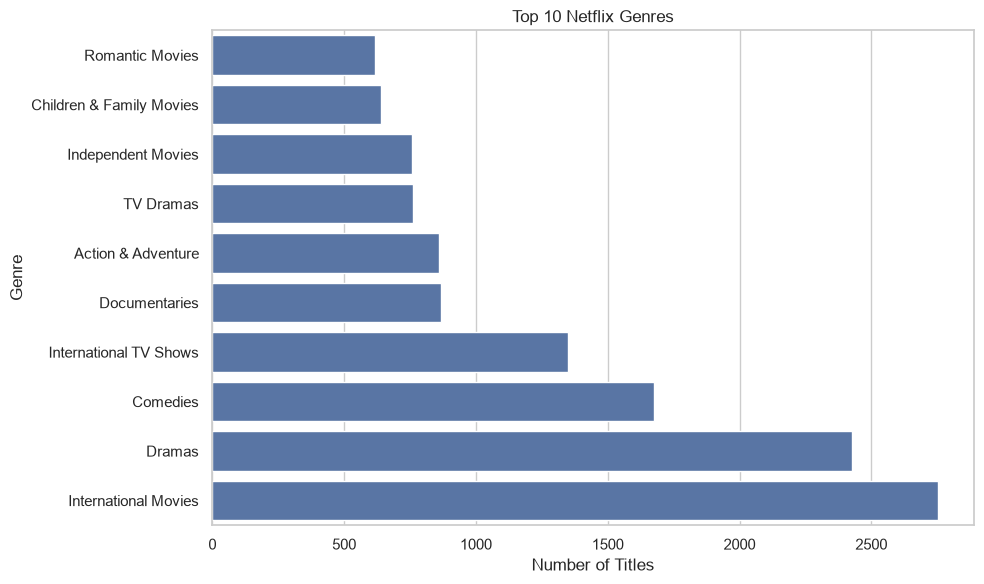

In [13]:
plt.figure(figsize=(10, 6))
sns.barplot(x=top_genres.values, y=top_genres.index)
plt.title('Top 10 Netflix Genres')
plt.xlabel('Number of Titles')
plt.ylabel('Genre')
plt.tight_layout()
plt.show()


## 8. Top Countries by Content Volume


In [14]:
country_data = df['country'].dropna().str.split(', ').explode()
top_countries = country_data.value_counts().head(10)
top_countries


country
United States     3689
India             1046
Unknown            831
United Kingdom     804
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Name: count, dtype: int64

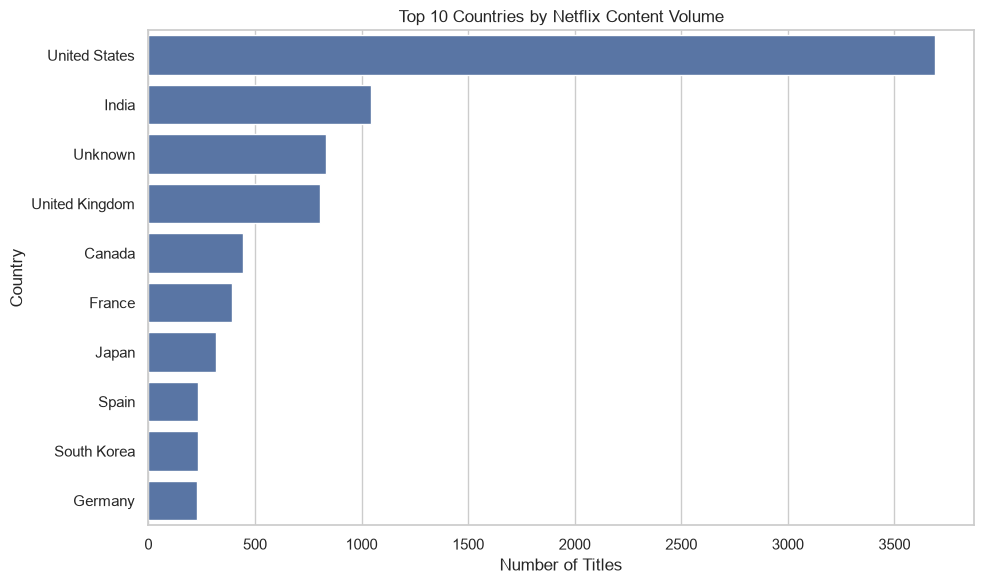

In [15]:
plt.figure(figsize=(10, 6))
sns.barplot(x=top_countries.values, y=top_countries.index)
plt.title('Top 10 Countries by Netflix Content Volume')
plt.xlabel('Number of Titles')
plt.ylabel('Country')
plt.tight_layout()
plt.show()


## 9. Country Content Heatmap


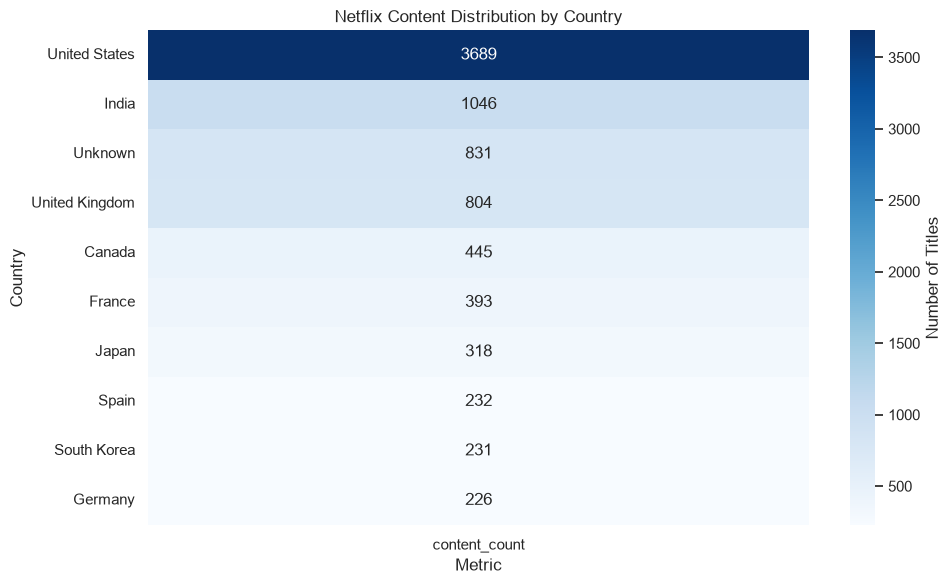

In [16]:
heatmap_data = pd.DataFrame({'content_count': top_countries}).sort_values('content_count', ascending=False)
plt.figure(figsize=(10, 6))
sns.heatmap(heatmap_data, annot=True, fmt='.0f', cmap='Blues', cbar_kws={'label': 'Number of Titles'})
plt.title('Netflix Content Distribution by Country')
plt.xlabel('Metric')
plt.ylabel('Country')
plt.tight_layout()
plt.show()


## 10. Release Decade Analysis


In [17]:
decade_counts = df['release_decade'].value_counts().sort_index()
decade_counts


release_decade
1920       1
1940      15
1950      11
1960      25
1970      70
1980     129
1990     274
2000     810
2010    5927
2020    1545
Name: count, dtype: int64

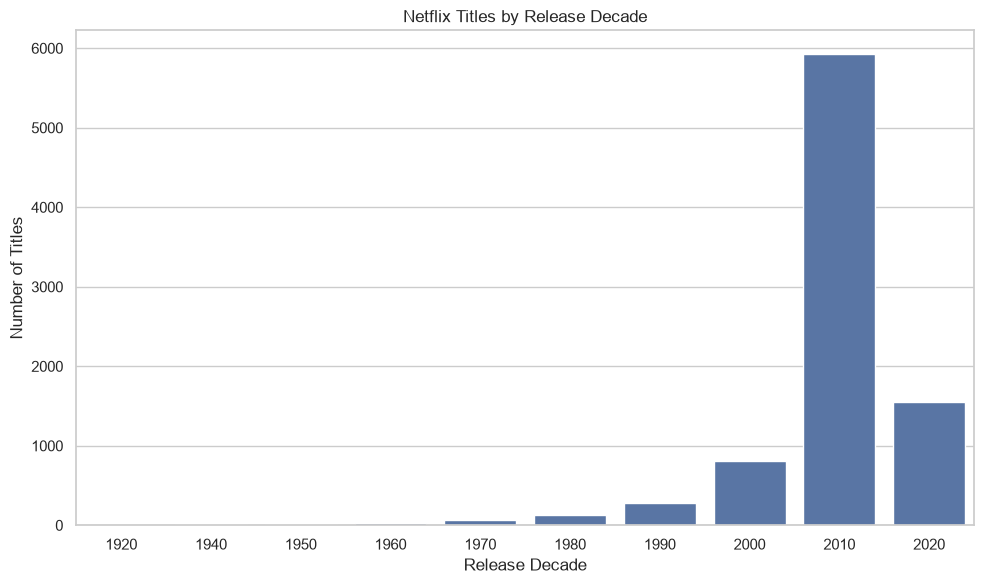

In [18]:
plt.figure(figsize=(10, 6))
sns.barplot(x=decade_counts.index.astype(str), y=decade_counts.values)
plt.title('Netflix Titles by Release Decade')
plt.xlabel('Release Decade')
plt.ylabel('Number of Titles')
plt.tight_layout()
plt.show()


## 11. Optional Trend Projection
This is an exploratory projection based on historical release-year counts, not a production forecasting model.


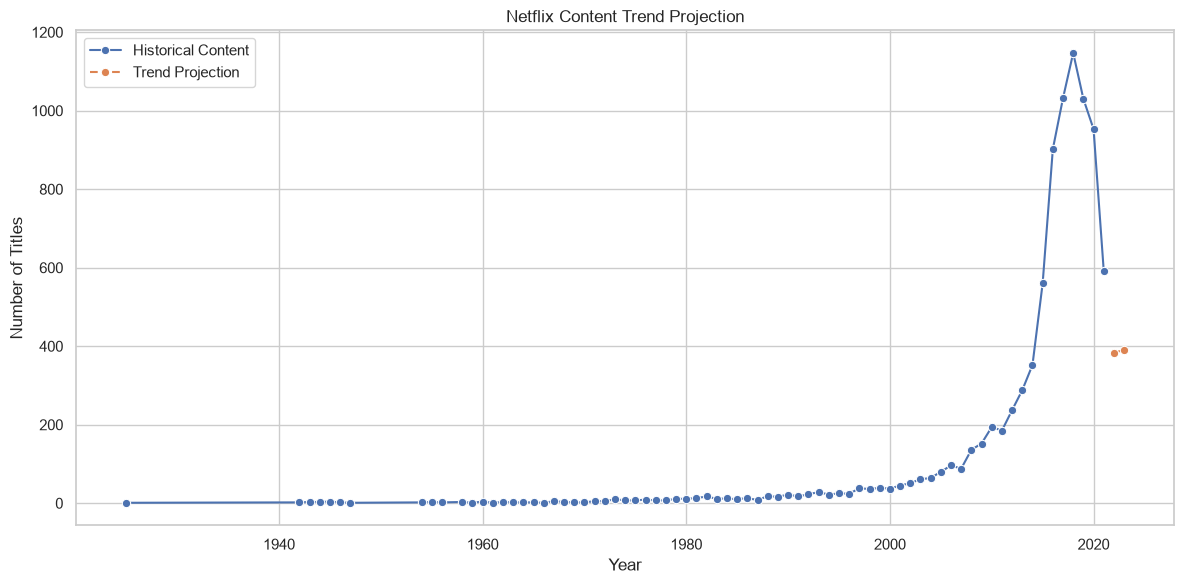

In [19]:
if len(yearly_content) >= 2:
    x = yearly_content['release_year']
    y = yearly_content['content_count']
    coefficients = np.polyfit(x, y, 1)
    trend_function = np.poly1d(coefficients)
    last_year = int(x.max())
    future_years = np.array([last_year + 1, last_year + 2])
    predicted_counts = np.clip(trend_function(future_years), 0, None)
    plt.figure(figsize=(12, 6))
    sns.lineplot(x=x, y=y, marker='o', label='Historical Content')
    sns.lineplot(x=future_years, y=predicted_counts, marker='o', linestyle='--', label='Trend Projection')
    plt.title('Netflix Content Trend Projection')
    plt.xlabel('Year')
    plt.ylabel('Number of Titles')
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print('Insufficient yearly data for trend projection.')


## 12. Key Findings

These findings are based on the 8,807 records in the supplied Netflix titles dataset. Percentages are rounded to one decimal place.

1. **Movies make up most of the catalog.** The dataset contains 6,131 movies (69.6%) and 2,676 TV shows (30.4%), so movies appear about 2.3 times as often as TV shows.

2. **The catalog is concentrated in titles released during the 2010s.** There are 5,927 titles released from 2010 through 2019, or 67.3% of all records. 2018 is the most represented release year, with 1,147 titles.

3. **International Movies and Dramas are the most common categories.** After splitting each title's `listed_in` field into its individual labels, International Movies leads with 2,752 titles, followed by Dramas (2,427) and Comedies (1,674). A title may belong to more than one category.

4. **The United States is the most represented country.** Splitting the `country` field into individual labels gives 3,689 titles for the United States, followed by India (1,046) and the United Kingdom (804). These are country-title credits, not exclusive totals: co-productions can count under multiple countries.

5. **Netflix additions peaked in 2019 in this dataset.** Of the titles with a recorded `date_added`, 2,016 were added in 2019, more than in 2020 (1,879) or 2021 (1,498). Addition year is not the same as release year, and 2021 is only partially represented in this dataset.

### Interpretation notes

- Release year and addition year describe different events and should not be treated as interchangeable trends.
- Genre and country totals can overlap because titles may have multiple labels or production countries.
- These results describe this dataset snapshot; they do not by themselves establish current Netflix availability or predict future catalog changes.


## 13. Conclusion

This exploratory analysis of 8,807 Netflix title records shows a catalog dominated by movies (69.6%), with 67.3% of titles released during the 2010s. International Movies and Dramas are the most frequent category labels, while the United States is the most represented country in the dataset. The largest number of recorded additions occurred in 2019.

These results describe this dataset snapshot, not Netflix's current catalog or audience demand. Genre and country counts overlap because a title can have multiple labels or production countries, and release year should not be confused with the year a title was added. The dataset and its simple trend projection are useful for descriptive EDA, but should not be treated as a validated forecast or evidence of popularity.
